In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
# Install compatible versions of the required libraries.

%pip -q install "transformers==4.48.3" "datasets==3.2.0" "evaluate==0.4.3" "accelerate==1.2.1"

Note: you may need to restart the kernel to use updated packages.


# Fine-Tuning Transformers for Question Answering

## 1. Introduction

Question Answering (QA) and text classification are two different Natural Language Processing (NLP) tasks. In text classification, a model assigns a predefined label to an input, such as positive or negative sentiment. In extractive Question Answering, the model receives a question and a passage of text, then identifies the answer by predicting its starting and ending token positions within the passage.

In this project, I fine-tune the pre-trained `bert-base-uncased` model on the Stanford Question Answering Dataset (SQuAD v1.1) using the Hugging Face Transformers library. The dataset provides questions, context passages, and answer spans. The model learns to predict the start and end positions of the correct answer in a given context.

The workflow includes dataset exploration, tokenization, answer-span alignment, fine-tuning with the Hugging Face Trainer API, validation using Exact Match (EM) and F1 scores, and testing on two custom question–answer examples. The objective is to understand how a pre-trained Transformer can be adapted to extract answers from textual context.


In [4]:
# Import standard Python libraries
import os
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import PyTorch
import torch

# Import Hugging Face libraries
from datasets import load_dataset
import evaluate

from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)

from tqdm.auto import tqdm

# Set fixed random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select GPU when available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Training will be slower on CPU.")

PyTorch version: 2.11.0+cu128
Selected device: cuda
GPU: Tesla T4


In [6]:
# Load the SQuAD v1.1 dataset from Hugging Face
dataset = load_dataset("squad")

# Display dataset structure and number of examples
print(dataset)
print("\nTraining examples:", len(dataset["train"]))
print("Validation examples:", len(dataset["validation"]))

# Inspect the first training example
sample = dataset["train"][0]

print("\nFirst training example:")
print(json.dumps(sample, indent=2, ensure_ascii=False))

# Display a few more samples to understand the data format
for i in range(3):
    example = dataset["train"][i]

    print("\n" + "=" * 70)
    print(f"Example {i + 1}")
    print("Question:", example["question"])
    print("Context:", example["context"][:500])
    print("Answer:", example["answers"]["text"])
    print("Answer start:", example["answers"]["answer_start"])

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/14.5M [00:00<?, ?B/s]

plain_text/validation-00000-of-00001.par(…):   0%|          | 0.00/1.82M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})

Training examples: 87599
Validation examples: 10570

First training example:
{
  "id": "5733be284776f41900661182",
  "title": "University_of_Notre_Dame",
  "context": "Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend \"Venite Ad Me Omnes\". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of 

In [7]:
# Name of the pre-trained BERT model
MODEL_NAME = "bert-base-uncased"

# Maximum number of tokens per feature
MAX_LENGTH = 384

# Overlap between consecutive context windows
DOC_STRIDE = 128

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Document stride:", DOC_STRIDE)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer loaded: bert-base-uncased
Maximum sequence length: 384
Document stride: 128


In [8]:
def find_answer_token_positions(input_ids, offsets, sequence_ids, answers):
    """
    Convert an answer's character offsets into token start/end positions.
    """

    # Handle an example with no answer
    # SQuAD v1.1 normally contains answerable questions.
    if not answers["answer_start"] or not answers["text"]:
        return 0, 0

    answer_start_char = answers["answer_start"][0]
    answer_text = answers["text"][0]
    answer_end_char = answer_start_char + len(answer_text)

    # Identify tokens belonging to the context, not the question or special tokens
    context_token_indices = [
        i for i, sequence_id in enumerate(sequence_ids)
        if sequence_id == 1
    ]

    if not context_token_indices:
        return 0, 0

    context_start = context_token_indices[0]
    context_end = context_token_indices[-1]

    # If the full answer is outside this context window, use CLS
    if (
        offsets[context_start][0] > answer_start_char
        or offsets[context_end][1] < answer_end_char
    ):
        return 0, 0

    # Find the token containing the answer's first character
    start_token = context_start

    while (
        start_token <= context_end
        and offsets[start_token][0] <= answer_start_char
    ):
        start_token += 1

    start_token -= 1

    # Find the token containing the answer's final character
    end_token = context_end

    while (
        end_token >= context_start
        and offsets[end_token][1] >= answer_end_char
    ):
        end_token -= 1

    end_token += 1

    # Safety check
    if start_token < context_start or end_token > context_end:
        return 0, 0

    if start_token > end_token:
        return 0, 0

    return start_token, end_token


print("Answer-span alignment function is ready.")

Answer-span alignment function is ready.


In [9]:
def preprocess_training_examples(examples):

    # Tokenize question-context pairs.
    # Only the context is truncated when a sequence exceeds MAX_LENGTH.
    tokenized = tokenizer(
        [question.strip() for question in examples["question"]],
        examples["context"],
        truncation="only_second",
        max_length=MAX_LENGTH,
        stride=DOC_STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False
    )

    # Each generated feature maps back to its original training example
    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized.pop("offset_mapping")

    start_positions = []
    end_positions = []

    for feature_index, sample_index in enumerate(sample_mapping):

        # Identify which tokens belong to the context
        sequence_ids = tokenized.sequence_ids(feature_index)

        # Retrieve the original answer annotations
        answers = examples["answers"][sample_index]

        # Align answer characters with token positions
        start_position, end_position = find_answer_token_positions(
            tokenized["input_ids"][feature_index],
            offset_mapping[feature_index],
            sequence_ids,
            answers
        )

        start_positions.append(start_position)
        end_positions.append(end_position)

    # Trainer expects these labels when fine-tuning a QA model
    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions

    return tokenized


# Process the training partition
train_features = dataset["train"].map(
    preprocess_training_examples,
    batched=True,
    remove_columns=dataset["train"].column_names,
    desc="Tokenizing training examples"
)

print("Original training examples:", len(dataset["train"]))
print("Tokenized training features:", len(train_features))
print("\nExample feature keys:", train_features.column_names)

# Inspect the first feature's answer positions
print("\nExample start position:", train_features[0]["start_positions"])
print("Example end position:", train_features[0]["end_positions"])

Tokenizing training examples:   0%|          | 0/87599 [00:00<?, ? examples/s]

Original training examples: 87599
Tokenized training features: 88524

Example feature keys: ['input_ids', 'token_type_ids', 'attention_mask', 'start_positions', 'end_positions']

Example start position: 130
Example end position: 137


In [10]:
def preprocess_validation_examples(examples):

    tokenized = tokenizer(
        [question.strip() for question in examples["question"]],
        examples["context"],
        truncation="only_second",
        max_length=MAX_LENGTH,
        stride=DOC_STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False
    )

    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized["offset_mapping"]

    example_ids = []
    start_positions = []
    end_positions = []
    filtered_offsets = []

    for feature_index, sample_index in enumerate(sample_mapping):

        sequence_ids = tokenized.sequence_ids(feature_index)
        answers = examples["answers"][sample_index]

        # Preserve the link between this feature and its original question
        example_ids.append(examples["id"][sample_index])

        # Add validation labels so Trainer can report validation loss
        start_position, end_position = find_answer_token_positions(
            tokenized["input_ids"][feature_index],
            offset_mapping[feature_index],
            sequence_ids,
            answers
        )

        start_positions.append(start_position)
        end_positions.append(end_position)

        # Retain character offsets only for context tokens.
        # Question and special-token offsets are set to None.
        current_offsets = []

        for token_index, offset in enumerate(offset_mapping[feature_index]):
            if sequence_ids[token_index] == 1:
                current_offsets.append(offset)
            else:
                current_offsets.append(None)

        filtered_offsets.append(current_offsets)

    tokenized["offset_mapping"] = filtered_offsets
    tokenized["example_id"] = example_ids
    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions

    return tokenized


# Process validation data
validation_features = dataset["validation"].map(
    preprocess_validation_examples,
    batched=True,
    remove_columns=dataset["validation"].column_names,
    desc="Tokenizing validation examples"
)

print("Original validation examples:", len(dataset["validation"]))
print("Tokenized validation features:", len(validation_features))

# Keep a metadata-rich version for answer reconstruction.
# Remove these metadata fields from the copy supplied to Trainer.
metadata_columns = ["example_id", "offset_mapping"]

validation_features_for_trainer = validation_features.remove_columns(
    metadata_columns
)

print(
    "Validation features supplied to Trainer:",
    len(validation_features_for_trainer)
)
print(
    "Trainer feature columns:",
    validation_features_for_trainer.column_names
)

Tokenizing validation examples:   0%|          | 0/10570 [00:00<?, ? examples/s]

Original validation examples: 10570
Tokenized validation features: 10784
Validation features supplied to Trainer: 10784
Trainer feature columns: ['input_ids', 'token_type_ids', 'attention_mask', 'start_positions', 'end_positions']


In [11]:
# Load a pre-trained BERT model with a question-answering head.
# The model will be fine-tuned on SQuAD start/end token labels.

model = AutoModelForQuestionAnswering.from_pretrained(MODEL_NAME)

model.to(DEVICE)

# Create a dynamic padding collator
# Each batch is padded to its own longest sequence.
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True
)

print("Question-answering model loaded.")
print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print("Number of model parameters:", sum(p.numel() for p in model.parameters()))

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForQuestionAnswering were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['qa_outputs.bias', 'qa_outputs.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Question-answering model loaded.
Model: bert-base-uncased
Device: cuda
Number of model parameters: 108893186


In [12]:
# Choose the batch size depending on available hardware
TRAIN_BATCH_SIZE = 16 if torch.cuda.is_available() else 4

# Training configuration
training_args = TrainingArguments(
    output_dir="./qa_squad_checkpoints",

    # Required assignment hyperparameters
    num_train_epochs=2,
    learning_rate=3e-5,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=16 if torch.cuda.is_available() else 4,

    # Optimization and regularization
    weight_decay=0.01,
    warmup_ratio=0.1,
    lr_scheduler_type="linear",

    # Evaluate and save a checkpoint after every epoch
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,

    # Keep the checkpoint with the lowest validation loss
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Reproducibility and logging
    seed=SEED,
    data_seed=SEED,
    logging_steps=100,
    logging_strategy="steps",

    # Mixed precision reduces GPU memory when supported by CUDA
    fp16=torch.cuda.is_available(),

    # Avoid unnecessary external experiment-reporting integrations
    report_to="none"
)

print("Training configuration is ready.")
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)
print("Training batch size:", TRAIN_BATCH_SIZE)

Training configuration is ready.
Epochs: 2
Learning rate: 3e-05
Training batch size: 16


In [13]:
# Create the Hugging Face Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_features,
    eval_dataset=validation_features_for_trainer,
    data_collator=data_collator,
    tokenizer=tokenizer
)

# Start fine-tuning
training_start_time = time.time()

train_result = trainer.train()

total_training_seconds = time.time() - training_start_time

print("\nFine-tuning completed.")
print(f"Total training time: {total_training_seconds / 60:.2f} minutes")

# Save the best model selected by validation loss
FINAL_MODEL_DIR = "./qa_squad_finetuned"

trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("\nModel and tokenizer saved to:", FINAL_MODEL_DIR)

# Display the training summary
print("\nTraining summary:")
print(train_result.metrics)

/tmp/ipykernel_49/1405970917.py:2: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,1.055600,1.032763
2,0.811600,1.008957


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



Fine-tuning completed.
Total training time: 109.70 minutes

Model and tokenizer saved to: ./qa_squad_finetuned

Training summary:
{'train_runtime': 6581.4687, 'train_samples_per_second': 26.901, 'train_steps_per_second': 0.841, 'total_flos': 3.035542398220013e+16, 'train_loss': 1.1943105360554322, 'epoch': 2.0}


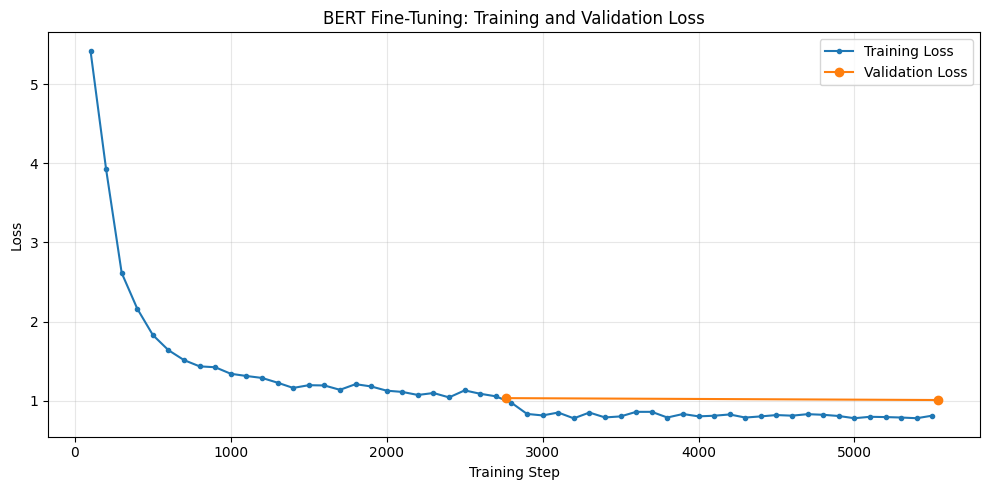

Training history saved.


In [14]:
# Convert the Trainer log history into a DataFrame
training_logs = pd.DataFrame(trainer.state.log_history)

# Extract training-loss and validation-loss records
train_loss_logs = training_logs.dropna(
    subset=["loss"]
) if "loss" in training_logs.columns else pd.DataFrame()

eval_loss_logs = training_logs.dropna(
    subset=["eval_loss"]
) if "eval_loss" in training_logs.columns else pd.DataFrame()

# Plot training and validation loss
plt.figure(figsize=(10, 5))

if not train_loss_logs.empty:
    plt.plot(
        train_loss_logs["step"],
        train_loss_logs["loss"],
        label="Training Loss",
        marker="."
    )

if not eval_loss_logs.empty:
    plt.plot(
        eval_loss_logs["step"],
        eval_loss_logs["eval_loss"],
        label="Validation Loss",
        marker="o"
    )

plt.title("BERT Fine-Tuning: Training and Validation Loss")
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save the training history
training_logs.to_csv(
    "QA_SQuAD_Training_History.csv",
    index=False
)

print("Training history saved.")

In [15]:
from collections import defaultdict

def postprocess_qa_predictions(
    examples,
    features,
    raw_predictions,
    n_best_size=20,
    max_answer_length=30
):
    """
    Convert start/end logits into readable answer strings.

    Multiple context windows can belong to the same original question.
    The candidate with the highest combined start/end score is selected.
    """

    all_start_logits, all_end_logits = raw_predictions

    # Map every original question ID to its validation features
    features_per_example = defaultdict(list)

    for feature_index, feature in enumerate(features):
        features_per_example[feature["example_id"]].append(feature_index)

    predictions = []

    for example in tqdm(examples, desc="Reconstructing answers"):

        example_id = example["id"]
        context = example["context"]

        best_score = -float("inf")
        best_text = ""

        feature_indices = features_per_example.get(example_id, [])

        for feature_index in feature_indices:

            start_logits = all_start_logits[feature_index]
            end_logits = all_end_logits[feature_index]

            offsets = features[feature_index]["offset_mapping"]

            # Inspect the most likely start and end positions
            top_start_indices = np.argsort(start_logits)[
                -n_best_size:
            ][::-1]

            top_end_indices = np.argsort(end_logits)[
                -n_best_size:
            ][::-1]

            for start_index in top_start_indices:

                # Ignore positions outside this feature's offset mapping
                if start_index >= len(offsets):
                    continue

                # Question and special-token offsets were removed
                if offsets[start_index] is None:
                    continue

                for end_index in top_end_indices:

                    if end_index >= len(offsets):
                        continue

                    if offsets[end_index] is None:
                        continue

                    # A valid answer must be ordered and reasonably short
                    if end_index < start_index:
                        continue

                    if end_index - start_index + 1 > max_answer_length:
                        continue

                    start_char = offsets[start_index][0]
                    end_char = offsets[end_index][1]

                    if end_char <= start_char:
                        continue

                    # Extract the candidate from the original context
                    candidate_text = context[start_char:end_char]

                    # Combine the start and end logits
                    score = (
                        float(start_logits[start_index])
                        + float(end_logits[end_index])
                    )

                    if score > best_score:
                        best_score = score
                        best_text = candidate_text

        predictions.append({
            "id": example_id,
            "prediction_text": best_text.strip()
        })

    return predictions


print("Answer reconstruction function is ready.")

Answer reconstruction function is ready.


In [16]:
# Generate predictions for all tokenized validation features
print("Generating validation predictions...")

validation_output = trainer.predict(
    validation_features_for_trainer
)

# Trainer returns start logits and end logits
validation_logits = validation_output.predictions

# Convert feature-level predictions back into answer strings
validation_predictions = postprocess_qa_predictions(
    examples=dataset["validation"],
    features=validation_features,
    raw_predictions=validation_logits
)

# Load the official SQuAD v1.1 evaluation metric
squad_metric = evaluate.load("squad")

# Format the references as required by the evaluation metric
validation_references = [
    {
        "id": example["id"],
        "answers": example["answers"]
    }
    for example in dataset["validation"]
]

# Calculate Exact Match and token-level F1
validation_metrics = squad_metric.compute(
    predictions=validation_predictions,
    references=validation_references
)

print("\n" + "=" * 55)
print("SQuAD VALIDATION RESULTS")
print("=" * 55)

print(f"Exact Match (EM): {validation_metrics['exact_match']:.2f}")
print(f"F1 Score:         {validation_metrics['f1']:.2f}")

# Also show the model's final evaluation loss
print(
    "Validation Loss:",
    validation_output.metrics.get("test_loss", "Not available")
)

# Save validation metrics
with open("QA_SQuAD_Validation_Metrics.json", "w") as file:
    json.dump(validation_metrics, file, indent=2)

# Save predictions for later inspection
pd.DataFrame(validation_predictions).to_csv(
    "QA_SQuAD_Validation_Predictions.csv",
    index=False
)

print("\nValidation metrics and predictions saved.")

Generating validation predictions...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Reconstructing answers:   0%|          | 0/10570 [00:00<?, ?it/s]


SQuAD VALIDATION RESULTS
Exact Match (EM): 80.17
F1 Score:         87.75
Validation Loss: 1.0089569091796875

Validation metrics and predictions saved.


In [17]:
# Compare a few predicted answers with their reference answers

validation_example_lookup = {
    example["id"]: example
    for example in dataset["validation"]
}

comparison_rows = []

for prediction in validation_predictions[:10]:

    original = validation_example_lookup[prediction["id"]]

    reference_answers = original["answers"]["text"]

    comparison_rows.append({
        "Question": original["question"],
        "Predicted Answer": prediction["prediction_text"],
        "Reference Answer": " | ".join(reference_answers),
        "Context Excerpt": original["context"][:250]
    })

comparison_df = pd.DataFrame(comparison_rows)

pd.set_option("display.max_colwidth", 180)
display(comparison_df)

,Question,Predicted Answer,Reference Answer,Context Excerpt
0,Which NFL team represented the AFC at Super Bowl 50?,Denver Broncos,Denver Broncos | Denver Broncos | Denver Broncos,Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
1,Which NFL team represented the NFC at Super Bowl 50?,Carolina Panthers,Carolina Panthers | Carolina Panthers | Carolina Panthers,Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
2,Where did Super Bowl 50 take place?,"Santa Clara, California","Santa Clara, California | Levi's Stadium | Levi's Stadium in the San Francisco Bay Area at Santa Clara, California.",Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
3,Which NFL team won Super Bowl 50?,Denver Broncos,Denver Broncos | Denver Broncos | Denver Broncos,Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
4,What color was used to emphasize the 50th anniversary of the Super Bowl?,gold,gold | gold | gold,Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
5,What was the theme of Super Bowl 50?,golden anniversary,"""golden anniversary"" | gold-themed | ""golden anniversary",Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
6,What day was the game played on?,"February 7, 2016","February 7, 2016 | February 7 | February 7, 2016",Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
7,What is the AFC short for?,American Football Conference,American Football Conference | American Football Conference | American Football Conference,Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
8,What was the theme of Super Bowl 50?,golden anniversary,"""golden anniversary"" | gold-themed | gold",Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...
9,What does AFC stand for?,American Football Conference,American Football Conference | American Football Conference | American Football Conference,Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion...


In [18]:
def answer_question(question, context, max_answer_length=30):
    """
    Answer a question by extracting a text span from the supplied context.
    The model cannot use information outside the supplied context.
    """

    model.eval()

    # Tokenize the question and context
    inputs = tokenizer(
        question,
        context,
        truncation="only_second",
        max_length=MAX_LENGTH,
        return_offsets_mapping=True,
        return_tensors="pt"
    )

    # Save character offsets before passing model inputs to BERT
    offset_mapping = inputs.pop("offset_mapping")[0].tolist()

    # Identify tokens that belong to the context
    sequence_ids = inputs.sequence_ids(0)

    # Move input tensors to GPU or CPU
    model_inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    # Generate start and end logits
    with torch.inference_mode():
        outputs = model(**model_inputs)

    start_logits = outputs.start_logits[0].cpu().numpy()
    end_logits = outputs.end_logits[0].cpu().numpy()

    # Consider the most promising start and end candidates
    top_start_indices = np.argsort(start_logits)[-20:][::-1]
    top_end_indices = np.argsort(end_logits)[-20:][::-1]

    best_score = -float("inf")
    best_answer = ""

    for start_index in top_start_indices:

        # Start must be a context token
        if sequence_ids[start_index] != 1:
            continue

        for end_index in top_end_indices:

            # End must also be a context token
            if sequence_ids[end_index] != 1:
                continue

            if end_index < start_index:
                continue

            if end_index - start_index + 1 > max_answer_length:
                continue

            start_char = offset_mapping[start_index][0]
            end_char = offset_mapping[end_index][1]

            if end_char <= start_char:
                continue

            candidate = context[start_char:end_char].strip()

            score = (
                float(start_logits[start_index])
                + float(end_logits[end_index])
            )

            if score > best_score:
                best_score = score
                best_answer = candidate

    return best_answer


print("Custom question-answering function is ready.")

Custom question-answering function is ready.


In [20]:
# Two custom question-answering tests

custom_tests = [
    {
        "name": "Test 1: Theory of Relativity",
        "question": "Who developed the theory of relativity?",
        "context": (
            "Albert Einstein developed the theory of relativity "
            "in the early 20th century."
        ),
        "expected_answer": "Albert Einstein"
    },
    {
        "name": "Test 2: Discoveries of Marie Curie",
        "question": "Which two elements did Marie Curie discover with Pierre Curie?",
        "context": (
            "Marie Curie and Pierre Curie conducted pioneering research "
            "on radioactivity and discovered the elements polonium and radium."
        ),
        "expected_answer": "polonium and radium"
    }
]

custom_test_results = []

for test in custom_tests:

    print("\n" + "=" * 70)
    print(test["name"])
    print("=" * 70)

    print("Question:", test["question"])
    print("Context:", test["context"])

    predicted_answer = answer_question(
        test["question"],
        test["context"]
    )

    print("\nExpected answer:", test["expected_answer"])
    print("Predicted answer:", predicted_answer)

    # Case-insensitive exact-string comparison for this custom example
    exact_match_custom = (
        predicted_answer.strip().lower()
        == test["expected_answer"].strip().lower()
    )

    print("Exact string match:", exact_match_custom)

    custom_test_results.append({
        "Test": test["name"],
        "Question": test["question"],
        "Expected Answer": test["expected_answer"],
        "Predicted Answer": predicted_answer,
        "Exact String Match": exact_match_custom
    })

custom_results_df = pd.DataFrame(custom_test_results)

print("\nCUSTOM TEST SUMMARY")
display(custom_results_df)

custom_results_df.to_csv(
    "QA_SQuAD_Custom_Test_Results.csv",
    index=False
)


Test 1: Theory of Relativity
Question: Who developed the theory of relativity?
Context: Albert Einstein developed the theory of relativity in the early 20th century.

Expected answer: Albert Einstein
Predicted answer: Albert Einstein
Exact string match: True

Test 2: Discoveries of Marie Curie
Question: Which two elements did Marie Curie discover with Pierre Curie?
Context: Marie Curie and Pierre Curie conducted pioneering research on radioactivity and discovered the elements polonium and radium.

Expected answer: polonium and radium
Predicted answer: polonium and radium
Exact string match: True

CUSTOM TEST SUMMARY


,Test,Question,Expected Answer,Predicted Answer,Exact String Match
0,Test 1: Theory of Relativity,Who developed the theory of relativity?,Albert Einstein,Albert Einstein,True
1,Test 2: Discoveries of Marie Curie,Which two elements did Marie Curie discover with Pierre Curie?,polonium and radium,polonium and radium,True


In [21]:
# Generate a short reflection using the experiment's actual results

em_score = validation_metrics["exact_match"]
f1_score_value = validation_metrics["f1"]

custom_pass_count = sum(
    row["Exact String Match"]
    for row in custom_test_results
)

reflection_sentences = [
    (
        "In this assignment, I learned how extractive question answering "
        "differs from text classification because the model predicts answer "
        "spans rather than assigning predefined class labels."
    ),
    (
        f"After fine-tuning bert-base-uncased on SQuAD v1.1, "
        f"the model achieved a validation Exact Match score of "
        f"{em_score:.2f} and an F1 score of {f1_score_value:.2f}."
    ),
    (
        "Exact Match measures whether the normalized predicted answer "
        "matches a reference exactly, whereas F1 also gives credit for "
        "overlapping answer tokens."
    ),
    (
        "Tokenizing long contexts with overlapping windows and aligning "
        "answer character positions with token positions were important "
        "parts of preparing the dataset correctly."
    ),
    (
        f"In the two custom tests, {custom_pass_count} prediction(s) "
        "matched the expected answer exactly as a string; the examples "
        "helped me inspect the model's ability to extract answers "
        "from new contexts."
    ),
    (
        "Overall, this project helped me understand how a pre-trained "
        "Transformer can be fine-tuned for extractive question answering "
        "and evaluated using EM, F1, and qualitative prediction checks."
    )
]

reflection = " ".join(reflection_sentences)

print("REFLECTION")
print("=" * 70)
print(reflection)

print("\nNumber of sentences:", len(reflection_sentences))

with open(
    "QA_SQuAD_Reflection.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(reflection)

print("\nReflection saved to QA_SQuAD_Reflection.txt")

REFLECTION
In this assignment, I learned how extractive question answering differs from text classification because the model predicts answer spans rather than assigning predefined class labels. After fine-tuning bert-base-uncased on SQuAD v1.1, the model achieved a validation Exact Match score of 80.17 and an F1 score of 87.75. Exact Match measures whether the normalized predicted answer matches a reference exactly, whereas F1 also gives credit for overlapping answer tokens. Tokenizing long contexts with overlapping windows and aligning answer character positions with token positions were important parts of preparing the dataset correctly. In the two custom tests, 2 prediction(s) matched the expected answer exactly as a string; the examples helped me inspect the model's ability to extract answers from new contexts. Overall, this project helped me understand how a pre-trained Transformer can be fine-tuned for extractive question answering and evaluated using EM, F1, and qualitative pre

In [22]:
# Combine the primary results into one final report
final_report = {
    "model_name": MODEL_NAME,
    "dataset": "SQuAD v1.1",
    "training_epochs": training_args.num_train_epochs,
    "learning_rate": training_args.learning_rate,
    "training_batch_size": TRAIN_BATCH_SIZE,
    "max_sequence_length": MAX_LENGTH,
    "document_stride": DOC_STRIDE,
    "training_time_minutes": round(total_training_seconds / 60, 2),
    "validation_exact_match": round(
        validation_metrics["exact_match"], 4
    ),
    "validation_f1": round(
        validation_metrics["f1"], 4
    ),
    "custom_tests": custom_test_results
}

print("FINAL PROJECT SUMMARY")
print("=" * 60)
print(json.dumps(final_report, indent=2, ensure_ascii=False))

# Save report to JSON
with open(
    "QA_SQuAD_Final_Report.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_report, file, indent=2, ensure_ascii=False)

print("\nAll result files have been saved.")

FINAL PROJECT SUMMARY
{
  "model_name": "bert-base-uncased",
  "dataset": "SQuAD v1.1",
  "training_epochs": 2,
  "learning_rate": 3e-05,
  "training_batch_size": 16,
  "max_sequence_length": 384,
  "document_stride": 128,
  "training_time_minutes": 109.7,
  "validation_exact_match": 80.1703,
  "validation_f1": 87.7453,
  "custom_tests": [
    {
      "Test": "Test 1: Theory of Relativity",
      "Question": "Who developed the theory of relativity?",
      "Expected Answer": "Albert Einstein",
      "Predicted Answer": "Albert Einstein",
      "Exact String Match": true
    },
    {
      "Test": "Test 2: Discoveries of Marie Curie",
      "Question": "Which two elements did Marie Curie discover with Pierre Curie?",
      "Expected Answer": "polonium and radium",
      "Predicted Answer": "polonium and radium",
      "Exact String Match": true
    }
  ]
}

All result files have been saved.
